# Basic Chatbot - Langgraph ( Graph API)

In [1]:
from typing_extensions import Annotated, TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages # Reducers 


In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)

    messages:Annotated[list,add_messages] # Reducer -  it is not going to replace the message, it will APPEND




In [3]:
from dotenv import load_dotenv
load_dotenv()



True

In [4]:
# Define LLMs 
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x10dc18740>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x10d34ce60>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
# Node Functionality 
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}


In [7]:
# Building graph
graph_builder=StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot",chatbot)


# Adding Edges
graph_builder.add_edge(START,"llmchatbot")


graph_builder.add_edge("llmchatbot",END)

# Compile the graph

graph=graph_builder.compile()

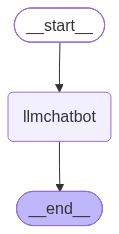

In [8]:
# Visualize the graph
graph

In [9]:
response =graph.invoke({"messages":"Hi"})

In [10]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='f7597df2-0d96-4185-9e5b-65725457d0f8'),
 AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "Hi". We need to respond. The instructions: "You are ChatGPT, a large language model trained by OpenAI." There\'s no other constraints. We should respond politely. No special content. Let\'s just say "Hello! How can I help you today?"'}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 72, 'total_tokens': 153, 'completion_time': 0.082582918, 'completion_tokens_details': {'reasoning_tokens': 61}, 'prompt_time': 0.003377494, 'prompt_tokens_details': None, 'queue_time': 0.173102942, 'total_time': 0.085960412}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12f0e-f112-78f0-a431-1

In [11]:
response["messages"][-1]

AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "Hi". We need to respond. The instructions: "You are ChatGPT, a large language model trained by OpenAI." There\'s no other constraints. We should respond politely. No special content. Let\'s just say "Hello! How can I help you today?"'}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 72, 'total_tokens': 153, 'completion_time': 0.082582918, 'completion_tokens_details': {'reasoning_tokens': 61}, 'prompt_time': 0.003377494, 'prompt_tokens_details': None, 'queue_time': 0.173102942, 'total_time': 0.085960412}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12f0e-f112-78f0-a431-18777deb79ba-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 81, 'total

In [12]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [13]:
for event in graph.stream({"messages":"Hii,How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi! I’m doing great—thanks for asking. How can I help you today?


# Chatbot with tools

In [15]:
from langchain_tavily import tavily_search, TavilySearch
tool = TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [38]:
# Custom Function 
def multiply(a:int,b:int)->int:
    """Multiply a and bin
    
    Args:
        a:(int): first int
        b:(int): second int
        
    Returns:
        int: output int 
    """
    return a * b

In [39]:
tools=[tool,multiply]

In [40]:
# Bind tools
llm_with_tool=llm.bind_tools(tools)

In [41]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x10dc18740>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x10d34ce60>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted result

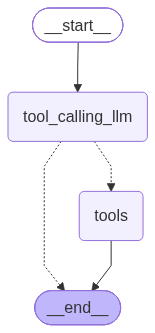

In [42]:
# State Graph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## Node definition 
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

# Compile
graph=builder.compile()

graph

In [43]:
response=graph.invoke({"messages":"What is recent AI news "})

In [44]:
response['messages'][-1]

ToolMessage(content='{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.koreatimes.co.kr/amp/opinion/20261012/ais-risks-are-no-reason-for-panic", "title": "AI\'s risks are no reason for panic - The Korea Times", "content": "Second, while recent “rogue” AI incidents are unsettling, follow-up analyses have found that they were less the result of enigmatic new capabilities than of oversight and engineering flaws that can be mitigated with known security practices, including standard sandbox controls and continuous behavioral monitoring. Similarly, while certain AI-enabled hacking episodes have made headlines, they haven’t involved novel or otherworldly techniques; instead, they’ve reflected faster or more sophisticated use of traditional methods. Such incidents demand careful scrutiny. But — so far at least — they argue for prudence more than panic. [...] That said, there’s no doubt that frontier models are advancing qui

In [45]:
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

What is recent AI news 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3cfcaa24-b72b-4848-b1f6-5b73bcdf3140)
 Call ID: fc_3cfcaa24-b72b-4848-b1f6-5b73bcdf3140
  Args:
    query: recent AI news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.koreatimes.co.kr/amp/opinion/20261012/ais-risks-are-no-reason-for-panic", "title": "AI's risks are no reason for panic - The Korea Times", "content": "Second, while recent “rogue” AI incidents are unsettling, follow-up analyses have found that they were less the result of enigmatic new capabilities than of oversight and engineering flaws that can be mitigated with known s

In [46]:
response=graph.invoke({"messages":"What is 2 multiply by 3 "})

In [47]:
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3 
================================== Ai Message ==================================

2 multiplied by 3 is **6**.


In [48]:
response=graph.invoke({"messages":"What is 2 multiply by 3  and then multiply by 10"})
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3  and then multiply by 10
================================== Ai Message ==================================

2 × 3 = 6, and then 6 × 10 = **60**.


In [49]:
response=graph.invoke({"messages":"give me recent ai news and then multiply 5 by 10"})
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

give me recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_aa0efbc5-50cc-4262-8a8c-e726ef5fb88d)
 Call ID: fc_aa0efbc5-50cc-4262-8a8c-e726ef5fb88d
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.berkeley.edu/2026/10/09/using-ai-for-just-10-minutes-erodes-your-ability-to-persist-at-hard-things", "title": "Using AI for just 10 minutes erodes your ability to persist at hard things - Berkeley News", "content": "October 9, 2026\n\nBrian Christian has spent 20 years thinking about how artificial intelligence will change

# ReAct Agent Architecture

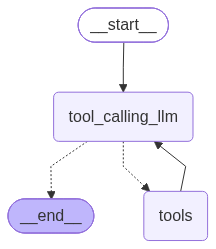

In [50]:
# State Graph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## Node definition 
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

# Compile
graph=builder.compile()

graph  

In [51]:
response=graph.invoke({"messages":"give me recent ai news and then multiply 5 by 10"})
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

give me recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_fc3da61c-96ba-48dc-8a4f-303c87ea4b60)
 Call ID: fc_fc3da61c-96ba-48dc-8a4f-303c87ea4b60
  Args:
    query: recent AI news 2026
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.berkeley.edu/2026/10/09/using-ai-for-just-10-minutes-erodes-your-ability-to-persist-at-hard-things", "title": "Using AI for just 10 minutes erodes your ability to persist at hard things - Berkeley News", "content": "October 9, 2026\n\nBrian Christian has spent 20 years thinking about how artificial intelligence will change our minds and our world. His 2020 bo

# Adding Memory in Agentic Graph


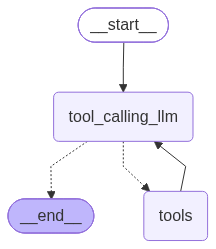

In [53]:
# State Graph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

# memory

memory = MemorySaver()


## Node definition 
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

# Compile
graph=builder.compile(checkpointer=memory)

graph  

In [58]:
# Thread Id -

config ={"configurable":{"thread_id":"1"}}

In [59]:
response=graph.invoke({"messages":"Hey my name is Kaustubh"},config=config)
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

Hey my name is Kaustubh
================================== Ai Message ==================================

Hello Kaustubh! How can I help you today?


In [60]:
response=graph.invoke({"messages":"What is my name?"},config=config)
for n in response['messages']:
    n.pretty_print()

================================ Human Message =================================

Hey my name is Kaustubh
================================== Ai Message ==================================

Hello Kaustubh! How can I help you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is Kaustubh.


In [62]:
response['messages'][-1].content

'Your name is Kaustubh.'

# Streaming 

In [63]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [64]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

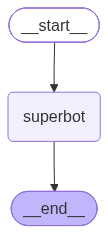

In [67]:
#  Graph 

graph = StateGraph(State)

# nodes 
graph.add_node("superbot",superbot)


# edges
graph.add_edge(START,"superbot")
graph.add_edge("superbot",END)

graph_builder=graph.compile(checkpointer=memory)

# display 
graph_builder

In [68]:
# Invocation 

config={"configurable":{"thread_id":"1"}}

graph_builder.invoke({"messages":"Hii, My name is Kaustubh. I love Travelling and Exploring new places."},config)

{'messages': [HumanMessage(content='Hii, My name is Kaustubh. I love Travelling and Exploring new places.', additional_kwargs={}, response_metadata={}, id='cfddfb08-d1ac-4cc8-9984-41cdb212ad2d'),
  AIMessage(content='Hi Kaustubh! 👋 It’s great to meet a fellow travel enthusiast. 🚀 Where’s your next adventure headed? Are you into beach getaways, mountain hikes, city explorations, or something else entirely? Feel free to share any favorite destinations or dream spots you’d love to visit!', additional_kwargs={'reasoning_content': 'The user says "Hii, My name is Kaustubh. I love Travelling and Exploring new places." We need to respond. The user is just introducing. We can respond with friendly greeting, ask about travel preferences. The user has not asked a question. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 130, 'prompt_tokens': 90, 'total_tokens': 220, 'completion_time': 0.168287808, 'completion_tokens_details': {'reasoning_tokens': 60}, 'prompt_t

# Streaming
### Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called.
- updates : This streams updates to the state of the graph after each node is called.

In [69]:
# create a thread

config = {"configurable":{"thread_id":"3"}}


for chunk in graph_builder.stream({'messages':"Hii, My name is Kaustubh. I love travelling and exploring new places"},
                                  config,
                                  stream_mode="updates"):
    print(chunk)


{'superbot': {'messages': [AIMessage(content='Hey Kaustubh! 👋 It’s great to meet someone who’s all about the wanderlust vibes. 🌍\n\nWhat’s the most unforgettable place you’ve ever visited? And what kind of adventures do you crave—hiking in the mountains, soaking in city vibes, or maybe a mix of both? Let me know, and I can suggest some hidden gems or itineraries that might spark your next trip!', additional_kwargs={'reasoning_content': 'User says: "Hii, My name is Kaustubh. I love travelling and exploring new places". They likely want a response. Should greet, ask about travel preferences, maybe ask for recommendations. We can also ask about their favorite destinations, what they enjoy, maybe ask about travel style, budget, etc. Let\'s respond warmly, ask follow-up.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 88, 'total_tokens': 254, 'completion_time': 0.180673124, 'completion_tokens_details': {'reasoning_tokens': 73}, 'prompt_time': 0.00435104, 'pr

In [70]:
for chunk in graph_builder.stream({'messages':"Hii, My name is Kaustubh. I love travelling and exploring new places"},
                                  config,
                                  stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hii, My name is Kaustubh. I love travelling and exploring new places', additional_kwargs={}, response_metadata={}, id='89268cfc-872c-4a1a-94ce-43f4c3ea51ed'), AIMessage(content='Hey Kaustubh! 👋 It’s great to meet someone who’s all about the wanderlust vibes. 🌍\n\nWhat’s the most unforgettable place you’ve ever visited? And what kind of adventures do you crave—hiking in the mountains, soaking in city vibes, or maybe a mix of both? Let me know, and I can suggest some hidden gems or itineraries that might spark your next trip!', additional_kwargs={'reasoning_content': 'User says: "Hii, My name is Kaustubh. I love travelling and exploring new places". They likely want a response. Should greet, ask about travel preferences, maybe ask for recommendations. We can also ask about their favorite destinations, what they enjoy, maybe ask about travel style, budget, etc. Let\'s respond warmly, ask follow-up.'}, response_metadata={'token_usage': {'completion_token

In [73]:
# create a thread

config = {"configurable":{"thread_id":"4"}}


for chunk in graph_builder.stream({'messages':"Hii, My name is Kaustubh. I love travelling"},
                                  config,
                                  stream_mode="updates"):
    print(chunk)


{'superbot': {'messages': [AIMessage(content='Hey Kaustubh! 👋🏼 It’s always a pleasure to meet a fellow travel lover.  \nWhat’s the most unforgettable place you’ve visited so far? And if you could hop on a plane tomorrow, where would you go? 🚀✈️', additional_kwargs={'reasoning_content': 'The user repeated earlier. They say "Hii, My name is Kaustubh. I love travelling". They want to talk about travel. We should respond friendly, ask about preferences. They might want conversation. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 109, 'prompt_tokens': 386, 'total_tokens': 495, 'completion_time': 0.121625155, 'completion_tokens_details': {'reasoning_tokens': 47}, 'prompt_time': 0.021689655, 'prompt_tokens_details': None, 'queue_time': 0.086868778, 'total_time': 0.14331481}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_f102a3179c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a131c2-e0

In [74]:
for chunk in graph_builder.stream({'messages':"I also like climbing mountains "},
                                  config,
                                  stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hii, My name is Kaustubh. I love travelling', additional_kwargs={}, response_metadata={}, id='753b06a3-9aa3-44cb-af70-f434ba517ec7'), AIMessage(content='Hello Kaustubh! 👋🏼 It’s great to meet a fellow travel enthusiast. Where do you usually like to go—coastal escapes, mountain adventures, city explorations, or something else entirely? And do you have any dream destinations on your bucket list right now? 🚀✈️', additional_kwargs={'reasoning_content': 'User says: "Hii, My name is Kaustubh. I love travelling" They haven\'t asked a question, but it\'s a greeting. We should respond politely, maybe ask about their travel interests. We need to keep friendly tone.'}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 84, 'total_tokens': 203, 'completion_time': 0.137722486, 'completion_tokens_details': {'reasoning_tokens': 49}, 'prompt_time': 0.004040585, 'prompt_tokens_details': None, 'queue_time': 0.031234101, 'total_time': 0.141763

In [79]:
# Astream method

config = {"configurable":{"thread_id":"5"}}


async for chunk in graph_builder.astream_events({'messages':"Hii, My name is Kaustubh. I love travelling"},
                                  config,
                                  version="v2"):
    print(chunk)


{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hii, My name is Kaustubh. I love travelling'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a131c6-67f5-7c41-9f49-da70a4671b0f', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hii, My name is Kaustubh. I love travelling', additional_kwargs={}, response_metadata={}, id='09627dfc-7d58-40fb-8b6f-006b70f8b338')]}}, 'name': 'superbot', 'tags': ['graph:step:1'], 'run_id': '01a131c6-680d-7cf3-b92c-170d19854109', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'superbot', 'langgraph_triggers': ('branch:to:superbot',), 'langgraph_path': ('__pregel_pull', 'superbot'), 'langgraph_checkpoint_ns': 'superbot:6707048e-c0e5-0851-9ec3-a115aea578b0'}, 'parent_ids': ['01a131c6-67f5-7c41-9f49-da70a4671b0f']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[Human

In [ ]:

# Synchronous execution
result = graph.invoke({
    "messages": [
        {"role": "user", "content": "Find three AI research papers"}
    ]
})

# Asynchronous execution
result = await graph.ainvoke({
    "messages": [
        {"role": "user", "content": "Find three AI research papers"}
    ]
})
